# kMC 3D: primeros resultados

Primer notebook del motor tridimensional `3DkMC/kmc3d` (diseño y fases en
`3DkMC/PLAN_3DkMC.md`). A diferencia de la línea (2+1)D de `src/`, aquí la
configuración es la ocupación de cada sitio de una red 3D: el cristal es **finito** y
crece (o se disuelve) **por todas sus caras**, con voladizos y huecos permitidos. La
anisotropía sale de un **grafo de enlaces**: cada tipo de enlace es un vector de red
con su energía φ/kT, y las caras se distinguen por los enlaces que cortan.

| § | Contenido |
|---|---|
| 1 | Configuración |
| 2 | Grafos: Kossel y β-hematina, teoría de energía de unión |
| 3 | Validación con Kossel: tamaño crítico (Gibbs-Thomson) y caras lisas frente a rugosas |
| 4 | Anisotropía con cubitos: aguja a lo largo del enlace fuerte |
| 5 | β-hematina: velocidades por cara, forma y sensibilidad a las energías |
| 6 | Superficie de una cara con los observables de `src.analysis` |
| 7 | Probabilidad de unión por tipo de sitio (análogo 3D de la Fig. 8) |
| 8 | Analizar corridas guardadas con `scripts/run_3d.py` |
| 9 | Conclusiones |

**Unidades.** Energías en kT; Δμ/kT = ln(1 + σ); tiempo en 1/k0 (k0 = 1); distancias en
unidades de la celda (1 para los cubitos, Å para β-hematina).

**Tasas** (`kmc3d.rates`). ΔG = −[Δμ + (E − E_kink)] es el cambio de energía libre al
unir una unidad a un sitio de energía de enlace E, y E_kink = Σφ:
- `gilmer`: k+ = k0 e^{Δμ} igual en todos los sitios, y k− = k0 e^{−(E − E_kink)};
- `symmetric`: k± = k0 e^{±(Δμ + E − E_kink)/2}, del tipo de MONTY/CrystalGrower.

Las dos cumplen balance detallado: tienen el mismo equilibrio y distinta cinética.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz de 3DkMC: la carpeta que contiene kmc3d/ (funciona desde notebooks/ o desde 3DkMC/)
ROOT_3D = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kmc3d").is_dir())
sys.path.insert(0, str(ROOT_3D))

from kmc3d import KMC3D, SplitRates, presets, seeds          # noqa: E402
from kmc3d import analysis as an, viz                         # noqa: E402

# Figuras y tablas de este notebook
OUT = ROOT_3D / "outputs" / "01_primeros_resultados"
GUARDAR = True
if GUARDAR:
    OUT.mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    # Guarda la figura en OUT si GUARDAR = True
    if GUARDAR:
        fig.savefig(OUT / f"{nombre}.png", dpi=150, bbox_inches="tight")


# Paleta categórica fija (orden estable, nunca cíclica) y marcadores por serie
COLORES = viz.PALETTE
MARCAS = viz.MARKERS
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
T0_NOTEBOOK = time.perf_counter()

## 2. Grafos de enlaces y teoría de energía de unión

Para una cara (hkl), los enlaces con (hkl)·v = 0 quedan **dentro** de la capa
(E_slice) y el resto la **cruzan** (E_att, energía liberada al unirse una capa por
unidad). Siempre E_slice + E_att = E_cr = Σφ. El modelo de Hartman-Perdok supone
R_hkl ∝ |E_att|.

El carácter de la cara es **F** (plana) si los enlaces de la capa forman una red 2D,
**S** (escalonada) si solo forman cadenas y **K** (con kinks) si no hay ninguno.

**Kossel** (cúbico simple, φ igual en x, y, z) es la comprobación clásica: {100} F,
{110} S, {111} K.

In [2]:
kossel = presets.kossel(2.0)
kossel.face_table([(1, 0, 0), (1, 1, 0), (1, 1, 1)])

,hkl,h,k,l,d_hkl,E_slice,E_att,E_att_frac,caracter,R_att_rel
0,(100),1,0,0,1.000,4.0,-2.0,0.333,F,1.0
1,(110),1,1,0,0.707,2.0,-4.0,0.667,S,2.0
2,(111),1,1,1,0.577,0.0,-6.0,1.000,K,3.0


**β-hematina.** Celda triclínica P-1 real (Pagola et al. 2000), con un dímero de hemo
por celda como unidad de crecimiento. Los siete vectores de enlace más cortos tienen
energías efectivas **provisionales** (`presets.BETA_HEMATIN_ENERGIES_PROVISIONAL`).
Se eligieron solo para que |E_att| ordene las caras como en la morfología observada:
aguja según c, {100} y {010} laterales, extremos {011} > {001} y sin {0-11}.

In [3]:
bh = presets.beta_hematin()
FACES_BH = presets.BETA_HEMATIN_FACES
display(bh.bond_table())
tabla_att = bh.face_table(FACES_BH).sort_values("R_att_rel", ignore_index=True)
tabla_att

,enlace,vector,longitud,phi_kT
0,[001],"(0, 0, 1)",8.040,2.4
1,[10-1],"(1, 0, -1)",15.382,1.0
2,[100],"(1, 0, 0)",12.196,0.4
3,[010],"(0, 1, 0)",14.684,0.9
4,[011],"(0, 1, 1)",16.714,0.5
5,[01-1],"(0, 1, -1)",16.768,1.1
6,[101],"(1, 0, 1)",13.790,0.3


,hkl,h,k,l,d_hkl,E_slice,E_att,E_att_frac,caracter,R_att_rel
0,(100),1,0,0,11.992,4.9,-1.7,0.258,F,1.000
1,(010),0,1,0,14.541,4.1,-2.5,0.379,F,1.471
2,(110),1,1,0,8.678,2.4,-4.2,0.636,S,2.471
3,(1-10),1,-1,0,9.957,2.4,-4.2,0.636,S,2.471
4,(101),1,0,1,6.305,1.9,-4.7,0.712,F,2.765
5,(011),0,1,1,6.937,1.5,-5.1,0.773,F,3.000
6,(001),0,0,1,7.982,1.3,-5.3,0.803,F,3.118
7,(10-1),1,0,-1,7.046,1.2,-5.4,0.818,F,3.176
8,(01-1),0,1,-1,7.058,0.9,-5.7,0.864,F,3.353


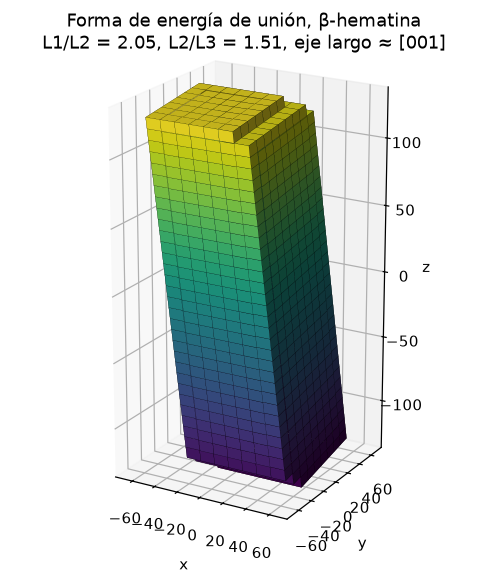

{'L1': np.float64(6.09),
 'L2': np.float64(2.96),
 'L3': np.float64(1.97),
 'L1/L2': 2.05,
 'L2/L3': 1.51,
 'L1/L3': 3.09,
 'eje_largo_uvw': (0, 0, 1),
 'angulo_eje_largo': 1.78,
 'n_muestras': 244827}

In [4]:
# Forma de energía de unión (Wulff con R ∝ |E_att|): descriptores del poliedro continuo
# y versión voxelizada en la celda real para el dibujo
desc_att = an.wulff_shape_descriptors(an.attachment_energy_rates(bh, FACES_BH), bh.cell)
forma_att = an.attachment_energy_morphology(bh, FACES_BH, size=150.0, normalize="largest")
fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(111, projection="3d")
viz.plot_voxels(forma_att, bh.cell, ax=ax, linewidth=0.1,
                title=f"Forma de energía de unión, β-hematina\n"
                      f"L1/L2 = {desc_att['L1/L2']:.2f}, L2/L3 = {desc_att['L2/L3']:.2f}, "
                      f"eje largo ≈ [{''.join(map(str, desc_att['eje_largo_uvw']))}]")
ax.view_init(elev=20, azim=-60)
guardar(fig, "forma_energia_union_bh")
plt.show()
{k: (round(v, 2) if isinstance(v, float) else v) for k, v in desc_att.items()}

## 3. Validación con Kossel

### 3.1 Tamaño crítico (Gibbs-Thomson)

Un cubo de lado L tiene G(L) = −Δμ L³ + 6γL², con γ = φ/2 por unidad de área en {100}.
El máximo está en **L\* = 2φ/Δμ**: los cubos más pequeños se disuelven aunque Δμ > 0
y los más grandes crecen. La entropía de los bordes rebaja un poco la barrera real,
así que L\* es una estimación.

Corridas de 40 000 eventos con tasas simétricas, φ = 2. Se clasifica cada corrida por
N_final/N_0.

In [5]:
PHI_GT = 2.0
g = presets.kossel(PHI_GT)
filas = []
for L in (4, 6, 8, 10, 12, 16):
    for dmu in (0.25, 0.5, 0.75, 1.0, 1.5):
        kmc = KMC3D(g, SplitRates.symmetric(g, dmu), seeds.cube(L), rng_seed=1)
        kmc.run(max_events=40_000, n_max=4 * L**3)
        filas.append({"L": L, "dmu": dmu, "N_final/N_0": kmc.n_occ / L**3})
gt = pd.DataFrame(filas)
# crece / se disuelve / indefinido (cambio < 5 % en la corrida)
gt["resultado"] = np.select([gt["N_final/N_0"] > 1.05, gt["N_final/N_0"] < 0.95],
                            ["crece", "se disuelve"], "indefinido")
gt.pivot(index="L", columns="dmu", values="N_final/N_0")

dmu,0.25,0.50,0.75,1.00,1.50
L,,,,,
4,0.000,0.000,0.000,4.000,4.0
6,0.000,0.000,4.000,4.000,4.0
8,0.000,4.000,4.000,4.000,4.0
10,0.000,3.890,4.000,4.000,4.0
12,0.000,3.041,4.000,4.000,4.0
16,0.903,1.841,2.879,3.896,4.0


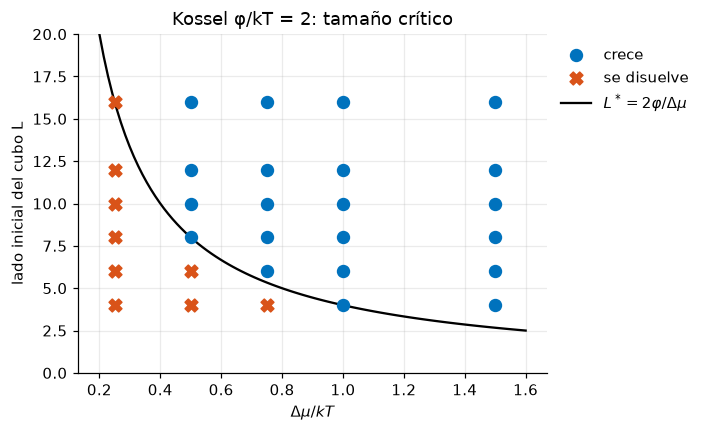

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4))
estilos = {"crece": dict(marker="o", color=COLORES[0], s=60),
           "se disuelve": dict(marker="X", color=COLORES[1], s=70),
           "indefinido": dict(marker="s", color="#888888", s=50)}
for res, kw in estilos.items():
    sub = gt[gt["resultado"] == res]
    if len(sub):
        ax.scatter(sub["dmu"], sub["L"], label=res, zorder=3, **kw)
x = np.linspace(0.2, 1.6, 100)
ax.plot(x, 2 * PHI_GT / x, color="k", lw=1.5, label=r"$L^* = 2\varphi/\Delta\mu$")
ax.set_xlabel(r"$\Delta\mu / kT$")
ax.set_ylabel("lado inicial del cubo L")
ax.set_ylim(0, 20)
ax.set_title(f"Kossel φ/kT = {PHI_GT:g}: tamaño crítico")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
guardar(fig, "kossel_tamano_critico")
plt.show()

### 3.2 Caras lisas frente a caras rugosas

Velocidad de las caras {100} frente a Δμ para tres valores de φ, con tasas de Gilmer.
En Kossel/SOS, la transición de rugosidad de {100} está en φ/kT ≈ 1.2 (acoplamiento
J = φ/2 y K_R ≈ 0.62). Por debajo, la cara es rugosa y R crece linealmente con Δμ.
Por encima es lisa: necesita nucleación 2D y R ≈ 0 a Δμ bajo.

Se miden dos posiciones de cara:
- **plano medio** del centro de la cara (`face_mean_series`, a partir de snapshots), que
  es la medida robusta;
- **plano más externo** (`face_series`, seguido por el motor en cada evento), que sube
  con la rugosidad y con unidades sueltas.

La referencia es la ley de Wilson-Frenkel para SOS, R/k+ = 1 − e^{−Δμ}. El modelo 3D
**no** es SOS: en una cara rugosa, los lados de los salientes también son sitios de
unión. Hay más de un sitio por columna, y con Gilmer cada sitio recibe k+, así que se
espera R/k+ por encima de Wilson-Frenkel.

In [7]:
FACES_AX = [(1, 0, 0), (0, 1, 0), (0, 0, 1)]
DMUS_K = [0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
filas = []
t0 = time.perf_counter()
for phi in (1.0, 2.0, 3.0):
    g = presets.kossel(phi)
    for dmu in DMUS_K:
        kmc = KMC3D(g, SplitRates.gilmer(g, dmu), seeds.cube(20), rng_seed=1, track_faces=FACES_AX)
        snaps, st = kmc.run(max_events=200_000, n_max=3 * 20**3, record_every=500,
                            snapshot_every=2_000)
        R_ext = an.face_growth_rates(an.face_series(st["history"], g, FACES_AX))["R"].mean()
        R_med = an.face_growth_rates(an.face_mean_series(snaps, g, FACES_AX))["R"].mean()
        filas.append({"phi": phi, "dmu": dmu, "R_medio/k+": R_med / np.exp(dmu),
                      "R_externo/k+": R_ext / np.exp(dmu), "eventos": kmc.n_events,
                      "N_final": kmc.n_occ})
rk = pd.DataFrame(filas)
print(f"{time.perf_counter() - t0:.0f} s")
rk.pivot(index="dmu", columns="phi", values=["R_medio/k+", "R_externo/k+"])

26 s


R_medio/k+                   R_externo/k+                  
phi         1.0    2.0        3.0          1.0    2.0        3.0
dmu                                                             
0.25      0.398  0.018 -7.872e-05        0.503  0.014 -2.633e-03
0.50      1.023  0.086  5.419e-05        1.114  0.095  8.239e-05
1.00      1.645  0.283  3.221e-02        2.518  0.286  3.589e-02
1.50      2.255  0.546  1.199e-01        2.856  0.551  1.250e-01
2.00      2.565  1.027  2.256e-01        3.496  1.190  2.570e-01
3.00      2.642  1.880  6.299e-01        2.913  2.621  7.114e-01

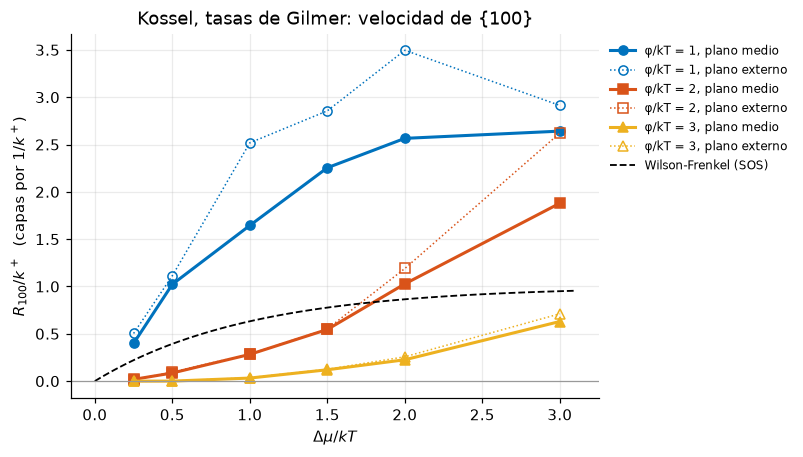

In [8]:
fig, ax = plt.subplots(figsize=(6.2, 4.3))
for i, phi in enumerate((1.0, 2.0, 3.0)):
    # trazo grueso y marcador lleno = plano medio; punteado y hueco = plano externo
    sub = rk[rk["phi"] == phi]
    ax.plot(sub["dmu"], sub["R_medio/k+"], color=COLORES[i], marker=MARCAS[i], lw=2,
            label=f"φ/kT = {phi:g}, plano medio")
    ax.plot(sub["dmu"], sub["R_externo/k+"], color=COLORES[i], marker=MARCAS[i], lw=1, ls=":",
            mfc="none", label=f"φ/kT = {phi:g}, plano externo")
x = np.linspace(0, 3.1, 100)
ax.plot(x, 1 - np.exp(-x), color="k", lw=1.2, ls="--", label="Wilson-Frenkel (SOS)")
ax.axhline(0, color="#999999", lw=0.8)
ax.set_xlabel(r"$\Delta\mu / kT$")
ax.set_ylabel(r"$R_{100} / k^+$  (capas por $1/k^+$)")
ax.set_title("Kossel, tasas de Gilmer: velocidad de {100}")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
guardar(fig, "kossel_R_vs_dmu")
plt.show()

## 4. Anisotropía con cubitos

Cubitos con φ_x = 1.2, φ_y = 1.8 y φ_z = 3.0, a Δμ = 1 y con tasas de Gilmer. Cada cara
{100}, {010}, {001} corta un solo tipo de enlace, así que E_att = φ_x, φ_y, φ_z. La cara
que corta el enlace más fuerte avanza más rápido y el cristal se alarga según z.

In [9]:
g_an = presets.anisotropic_cubic(1.2, 1.8, 3.0)
kmc_an = KMC3D(g_an, SplitRates.gilmer(g_an, 1.0), seeds.cube(8), rng_seed=1, track_faces=FACES_AX)
t0 = time.perf_counter()
snaps_an, st_an = kmc_an.run(max_events=600_000, n_max=30_000, record_every=1000,
                             snapshot_every=3_000)
print(f"{kmc_an.n_events} eventos en {time.perf_counter() - t0:.1f} s, N = {kmc_an.n_occ}")
R_an = an.face_growth_rates(an.face_mean_series(snaps_an, g_an, FACES_AX))
fam_an = R_an.groupby("familia", sort=False)[["R_familia", "R_rel"]].first()
comp = g_an.face_table(FACES_AX).set_index("hkl")[["E_att", "R_att_rel", "caracter"]].join(fam_an)
display(comp)
an.shape_descriptors(snaps_an[-1][1], g_an.cell)

260168 eventos en 3.0 s, N = 30000


,E_att,R_att_rel,caracter,R_familia,R_rel
hkl,,,,,
(100),-1.2,1.0,F,0.389,1.000
(010),-1.8,1.5,F,0.644,1.655
(001),-3.0,2.5,F,1.184,3.042


{'L1': np.float64(46.869717509280655),
 'L2': np.float64(29.334377712361167),
 'L3': np.float64(20.09808067473499),
 'L1/L2': 1.5977743918368617,
 'L2/L3': 1.4595611485049411,
 'L1/L3': 2.332049426401194,
 'eje_largo_uvw': (0, 0, 1),
 'angulo_eje_largo': 2.224860348407485,
 'N': 30000}

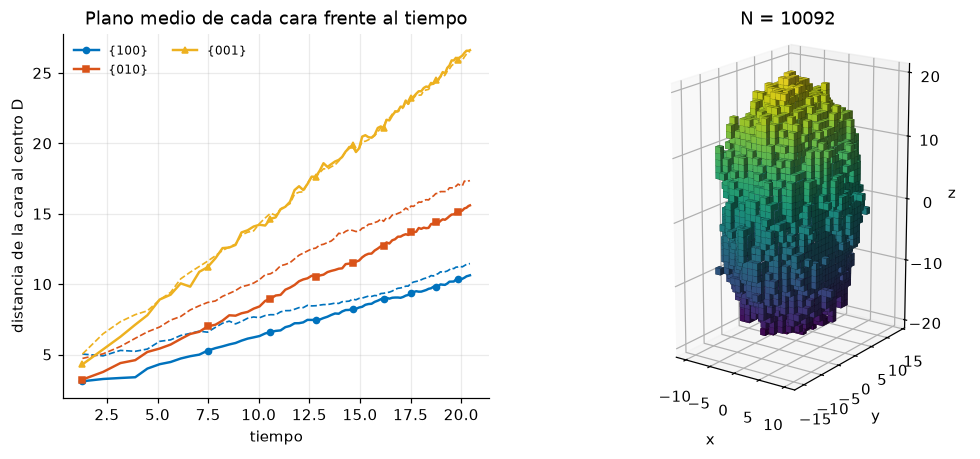

In [10]:
fig = plt.figure(figsize=(11, 4.3))
ax1 = fig.add_subplot(1, 2, 1)
viz.plot_face_series(an.face_mean_series(snaps_an, g_an, FACES_AX), ax=ax1,
                     title="Plano medio de cada cara frente al tiempo")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
# snapshot de ~10 000 unidades para el dibujo con vóxeles
i_vox = int(np.argmin([abs(len(c) - 10_000) for _, c in snaps_an]))
viz.plot_voxels(snaps_an[i_vox][1], g_an.cell, ax=ax2, linewidth=0.05,
                title=f"N = {len(snaps_an[i_vox][1])}")
ax2.view_init(elev=18, azim=-55)
guardar(fig, "cubitos_anisotropos")
plt.show()

## 5. β-hematina

### 5.1 Barrido en Δμ con los dos modelos de tasas

Se parte de una semilla esférica de radio 70 Å (unas 870 unidades) y se crece hasta
N = 40 000. Las velocidades por cara se miden con el plano medio (snapshots cada
10 000 eventos). En la tabla, `R_rel` está normalizada por la cara más lenta de cada
corrida; en la figura, por la {100}, como la predicción de energía de unión R ∝ |E_att|
(línea negra).

La "velocidad" de una cara que no aparece en el cristal es la del avance del cristal
en esa dirección (arista o vértice). Para la forma solo cuentan las caras lentas.

In [11]:
DMUS_BH = [0.75, 1.0, 1.5, 2.5]
MODELOS = ("symmetric", "gilmer")
filas, finales, probs = [], {}, []
t0 = time.perf_counter()
for modelo in MODELOS:
    for dmu in DMUS_BH:
        kmc = KMC3D(bh, getattr(SplitRates, modelo)(bh, dmu), seeds.sphere(70.0, bh.cell),
                    rng_seed=1, track_faces=FACES_BH)
        snaps, st = kmc.run(max_events=2_000_000, n_max=40_000, record_every=2000,
                            snapshot_every=10_000)
        R = an.face_growth_rates(an.face_mean_series(snaps, bh, FACES_BH))
        fam = R.groupby("familia", sort=False)["R_rel"].first()
        sh = an.shape_descriptors(snaps[-1][1], bh.cell)
        filas.append({"modelo": modelo, "dmu": dmu, "eventos": kmc.n_events,
                      "L1/L2": sh["L1/L2"], "L2/L3": sh["L2/L3"],
                      "eje_largo": "[" + "".join(map(str, sh["eje_largo_uvw"])) + "]",
                      "angulo": sh["angulo_eje_largo"], **fam.to_dict()})
        finales[(modelo, dmu)] = snaps[-1][1]
        # probabilidad de unión por número de enlaces en el estado final (§7)
        p = an.attachment_probabilities(kmc)
        probs.append(p.assign(modelo=modelo, dmu=dmu))
bh_scan = pd.DataFrame(filas)
print(f"{time.perf_counter() - t0:.0f} s")
if GUARDAR:
    bh_scan.to_csv(OUT / "bh_barrido.csv", index=False)
bh_scan

72 s


,modelo,dmu,eventos,L1/L2,L2/L3,eje_largo,angulo,(100),(010),(001),(011),(01-1),(101),(10-1),(110),(1-10)
0,symmetric,0.75,228627,1.314,2.318,[001],16.121,1.000,3.567,5.003,3.153,3.147,2.187,2.385,1.196,1.653
1,symmetric,1.00,140723,1.172,1.990,[01-2],17.311,1.000,3.485,3.782,2.613,2.528,1.786,1.866,1.270,1.669
2,symmetric,1.50,83807,1.092,1.636,[01-2],5.300,1.258,2.903,3.136,2.277,2.114,1.537,1.516,1.000,1.499
3,symmetric,2.50,52789,1.117,1.440,[01-1],2.974,1.263,1.942,1.771,1.236,1.043,1.100,1.015,1.127,1.000
4,gilmer,0.75,905155,1.166,2.158,[01-2],20.336,1.000,3.378,3.679,2.284,2.440,1.660,1.970,1.443,1.473
5,gilmer,1.00,550805,1.143,1.889,[01-2],21.273,1.000,2.328,2.798,1.828,1.723,1.391,1.419,1.018,1.137
6,gilmer,1.50,309023,1.112,1.600,[02-1],6.662,1.037,2.217,1.904,1.293,1.385,1.000,1.186,1.082,1.157
7,gilmer,2.50,146201,1.147,1.273,[01-1],3.356,2.525,3.034,2.662,2.240,2.138,1.446,1.476,1.000,1.980


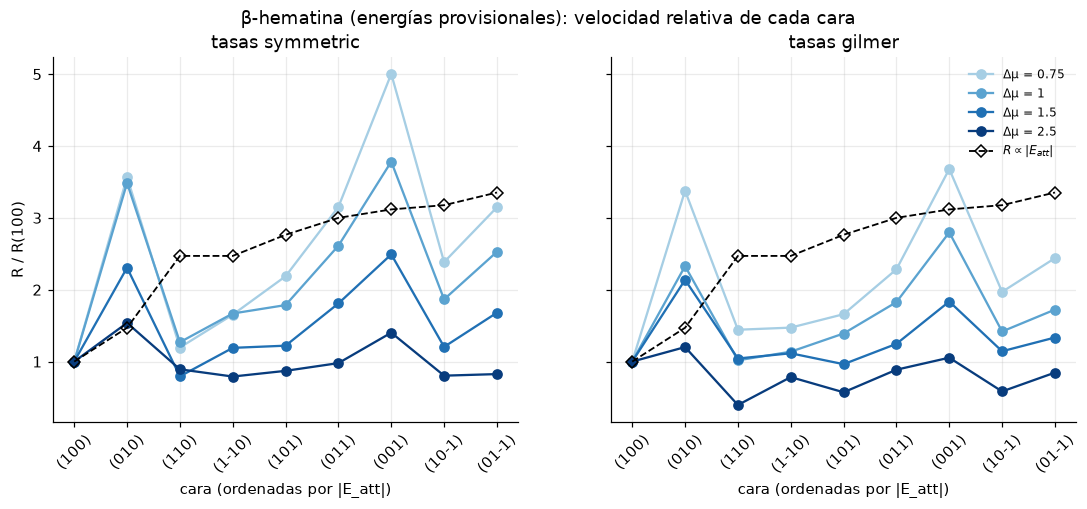

In [12]:
# Caras ordenadas por |E_att| (predicción de energía de unión)
orden = list(tabla_att["hkl"])
x = np.arange(len(orden))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
# Δμ es una magnitud: rampa secuencial de un solo tono (claro -> oscuro)
tonos = plt.get_cmap("Blues")(np.linspace(0.35, 0.95, len(DMUS_BH)))
for ax, modelo in zip(axes, MODELOS):
    for c, dmu in zip(tonos, DMUS_BH):
        fila = bh_scan[(bh_scan["modelo"] == modelo) & (bh_scan["dmu"] == dmu)].iloc[0]
        # normalizado por la (100), como la predicción de E_att (no por la cara más lenta)
        ax.plot(x, [fila[f] / fila["(100)"] for f in orden], color=c, marker="o", lw=1.5,
                label=f"Δμ = {dmu:g}")
    ax.plot(x, tabla_att["R_att_rel"], color="k", marker="D", mfc="none", lw=1.2, ls="--",
            label=r"$R \propto |E_{att}|$")
    ax.set_xticks(x, orden, rotation=45)
    ax.set_title(f"tasas {modelo}")
    ax.set_xlabel("cara (ordenadas por |E_att|)")
axes[0].set_ylabel("R / R(100)")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("β-hematina (energías provisionales): velocidad relativa de cada cara")
guardar(fig, "bh_R_por_cara")
plt.show()

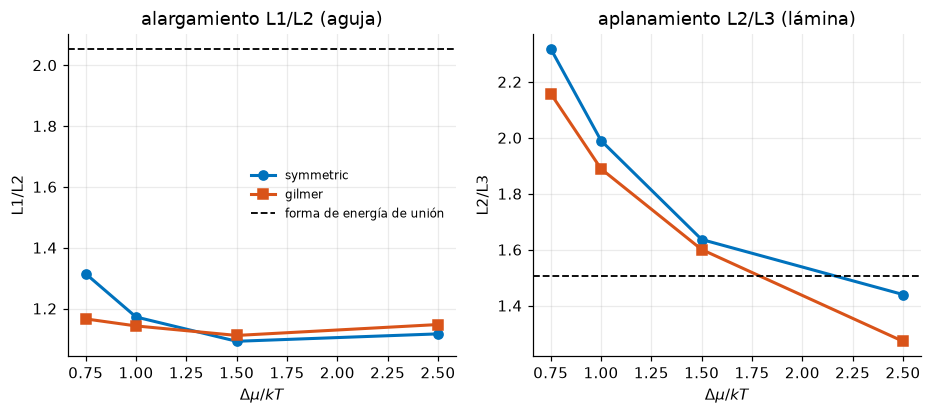

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, nombre in zip(axes, ("L1/L2", "L2/L3"),
                           ("alargamiento L1/L2 (aguja)", "aplanamiento L2/L3 (lámina)")):
    for i, modelo in enumerate(MODELOS):
        sub = bh_scan[bh_scan["modelo"] == modelo]
        ax.plot(sub["dmu"], sub[col], color=COLORES[i], marker=MARCAS[i], lw=2, label=modelo)
    ax.axhline(desc_att[col], color="k", ls="--", lw=1.2, label="forma de energía de unión")
    ax.set_xlabel(r"$\Delta\mu / kT$")
    ax.set_ylabel(col)
    ax.set_title(nombre)
axes[0].legend(frameon=False, fontsize=8)
guardar(fig, "bh_forma_vs_dmu")
plt.show()

### 5.2 Sensibilidad a las energías: hacia una aguja

Mismas condiciones (tasas simétricas, Δμ = 1) con tres juegos de energías:
- **base**: las provisionales;
- **[001] = 3.5**: apilamiento más fuerte, por lo que las caras que cortan c son más
  rápidas;
- **[001] = 3.5, ×1.3**: además, todas las energías ×1.3. Equivale a bajar la
  temperatura efectiva y hace las caras más lisas.

Las velocidades medidas en el kMC permiten construir la **forma de Wulff cinética**
(`morphology_from_rates`) y compararla con la forma simulada.

In [14]:
variantes = {"base": presets.beta_hematin(),
             "[001] = 3.5": presets.beta_hematin({"[001]": 3.5}),
             "[001] = 3.5, ×1.3": presets.beta_hematin({"[001]": 3.5}, scale=1.3)}
filas, formas = [], {}
for nombre, gv in variantes.items():
    kmc = KMC3D(gv, SplitRates.symmetric(gv, 1.0), seeds.sphere(70.0, gv.cell), rng_seed=1,
                track_faces=FACES_BH)
    snaps, st = kmc.run(max_events=2_000_000, n_max=40_000, record_every=2000,
                        snapshot_every=10_000)
    R = an.face_growth_rates(an.face_mean_series(snaps, gv, FACES_BH))
    sh = an.shape_descriptors(snaps[-1][1], gv.cell)
    # formas de Wulff (poliedros continuos): con las R medidas y con R ∝ |E_att|
    sw = an.wulff_shape_descriptors(an.family_rates(R), gv.cell)
    sa = an.wulff_shape_descriptors(an.attachment_energy_rates(gv, FACES_BH), gv.cell)
    filas.append({"energías": nombre, "eventos": kmc.n_events,
                  "kMC L1/L2": sh["L1/L2"], "kMC L2/L3": sh["L2/L3"],
                  "kMC eje": "[" + "".join(map(str, sh["eje_largo_uvw"])) + "]",
                  "Wulff cinético L1/L2": sw["L1/L2"], "Wulff cinético L2/L3": sw["L2/L3"],
                  "E_att L1/L2": sa["L1/L2"], "E_att L2/L3": sa["L2/L3"]})
    formas[nombre] = snaps
sens = pd.DataFrame(filas)
sens

,energías,eventos,kMC L1/L2,kMC L2/L3,kMC eje,Wulff cinético L1/L2,Wulff cinético L2/L3,E_att L1/L2,E_att L2/L3
0,base,140723,1.172,1.990,[01-2],1.035,2.175,2.054,1.507
1,[001] = 3.5,170307,1.991,2.055,[001],2.304,2.109,2.513,1.507
2,"[001] = 3.5, ×1.3",329175,6.244,1.997,[001],8.686,1442.767,2.513,1.507


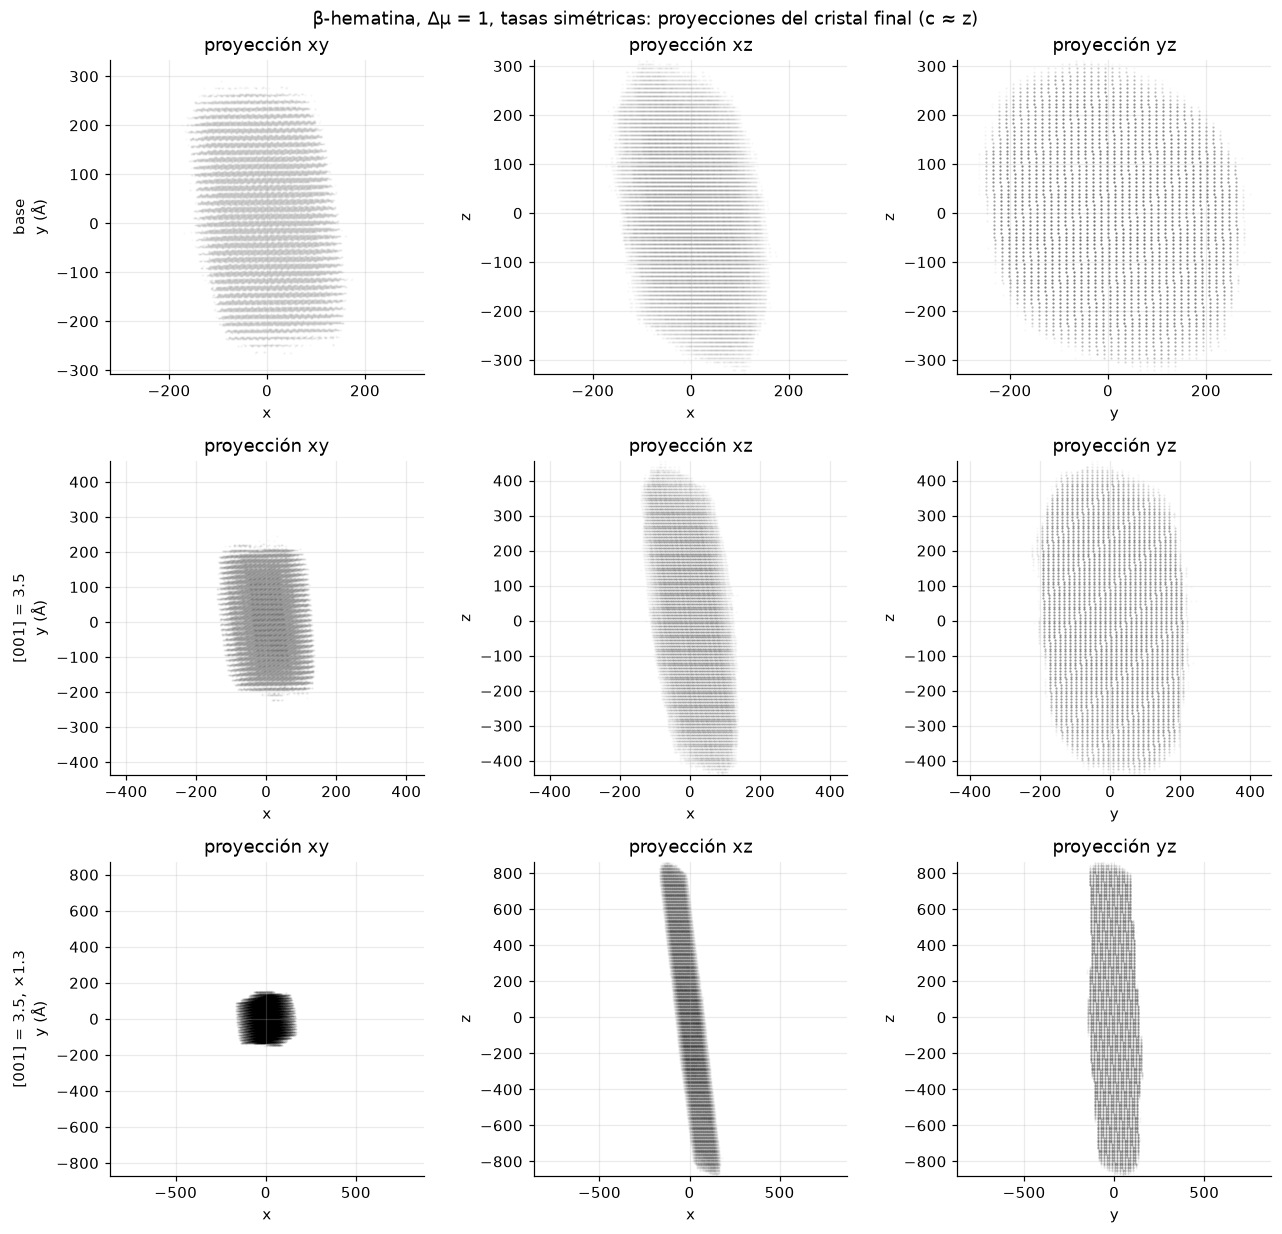

In [15]:
fig, axes = plt.subplots(len(formas), 3, figsize=(12, 3.8 * len(formas)))
for fila_ax, (nombre, snaps) in zip(axes, formas.items()):
    viz.plot_projections(snaps[-1][1], variantes[nombre].cell, axes=fila_ax)
    fila_ax[0].set_ylabel(f"{nombre}\ny (Å)")
fig.suptitle("β-hematina, Δμ = 1, tasas simétricas: proyecciones del cristal final (c ≈ z)")
fig.tight_layout()
guardar(fig, "bh_variantes_proyecciones")
plt.show()

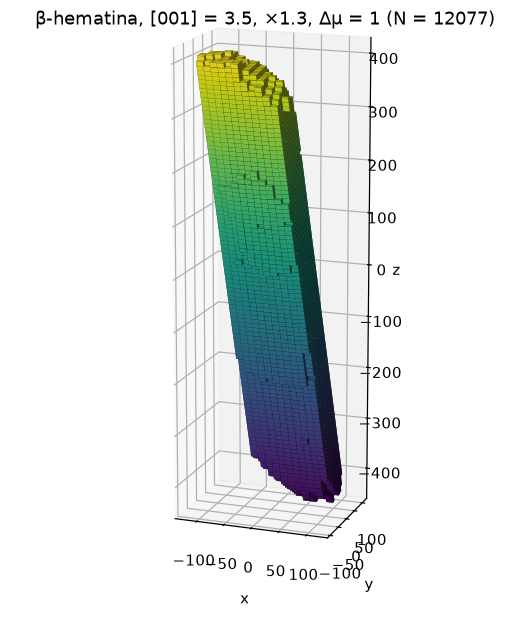

In [16]:
# Vista 3D (vóxeles con la celda triclínica) de la variante más alargada, a N ≈ 12 000
snaps = formas["[001] = 3.5, ×1.3"]
i_vox = int(np.argmin([abs(len(c) - 12_000) for _, c in snaps]))
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")
viz.plot_voxels(snaps[i_vox][1], bh.cell, ax=ax, linewidth=0.05,
                title=f"β-hematina, [001] = 3.5, ×1.3, Δμ = 1 (N = {len(snaps[i_vox][1])})")
ax.view_init(elev=15, azim=-70)
guardar(fig, "bh_voxeles")
plt.show()

### 5.3 Visualización dinámica y por caras

Los mismos snaps de la celda anterior (variante `[001] = 3.5, ×1.3`, Δμ = 1, tasas
simétricas):

- **Dinámica** (`viz.animate_growth_3d`, matplotlib): animación de la superficie del
  cristal en 3D con la celda triclínica real, un fotograma por snapshot (33). El
  reproductor (▶ / ❚❚, deslizador, velocidad) recorre el crecimiento y la cámara gira 3°
  por fotograma para que se vea la forma en 3D. El color es el tiempo de llegada de cada
  unidad: se ve qué partes del cristal crecieron en cada momento. No necesita WebGL ni
  plotly. También se guarda como HTML en `outputs/01_primeros_resultados/`. En un visor
  con WebGL, `kmc3d.viz_interactive.plot_growth_3d` (plotly) da la misma figura con
  rotación libre con el ratón.
- **Por caras** (`viz.plot_face_maps`): un mapa 2D de cada cara (hkl), vista desde fuera,
  del mismo snapshot (N ≈ 12 000). El color es la altura de cada columna respecto a la
  terraza principal de la cara (0): islas por encima (+1, +2, …), huecos y terrazas
  inferiores por debajo (−1, −2, …) y, en gris, aristas y caras vecinas. Cada panel
  tiene su propia escala; el título da el tamaño de la cara en columnas.

In [ ]:
from IPython.display import HTML

# Animación del crecimiento sin WebGL: un fotograma por snapshot, color = tiempo de
# llegada de cada unidad y la cámara girando 3° por fotograma
anim = viz.animate_growth_3d(snaps, bh.cell, color_by="arrival", azim_step=3.0,
                             figsize=(8, 10), title="β-hematina, [001] = 3.5, ×1.3, Δμ = 1")
html_anim = anim.to_jshtml()          # reproductor HTML + JS con los fotogramas en PNG
if GUARDAR:
    (OUT / "bh_crecimiento_3d.html").write_text(html_anim, encoding="utf-8")
HTML(html_anim)

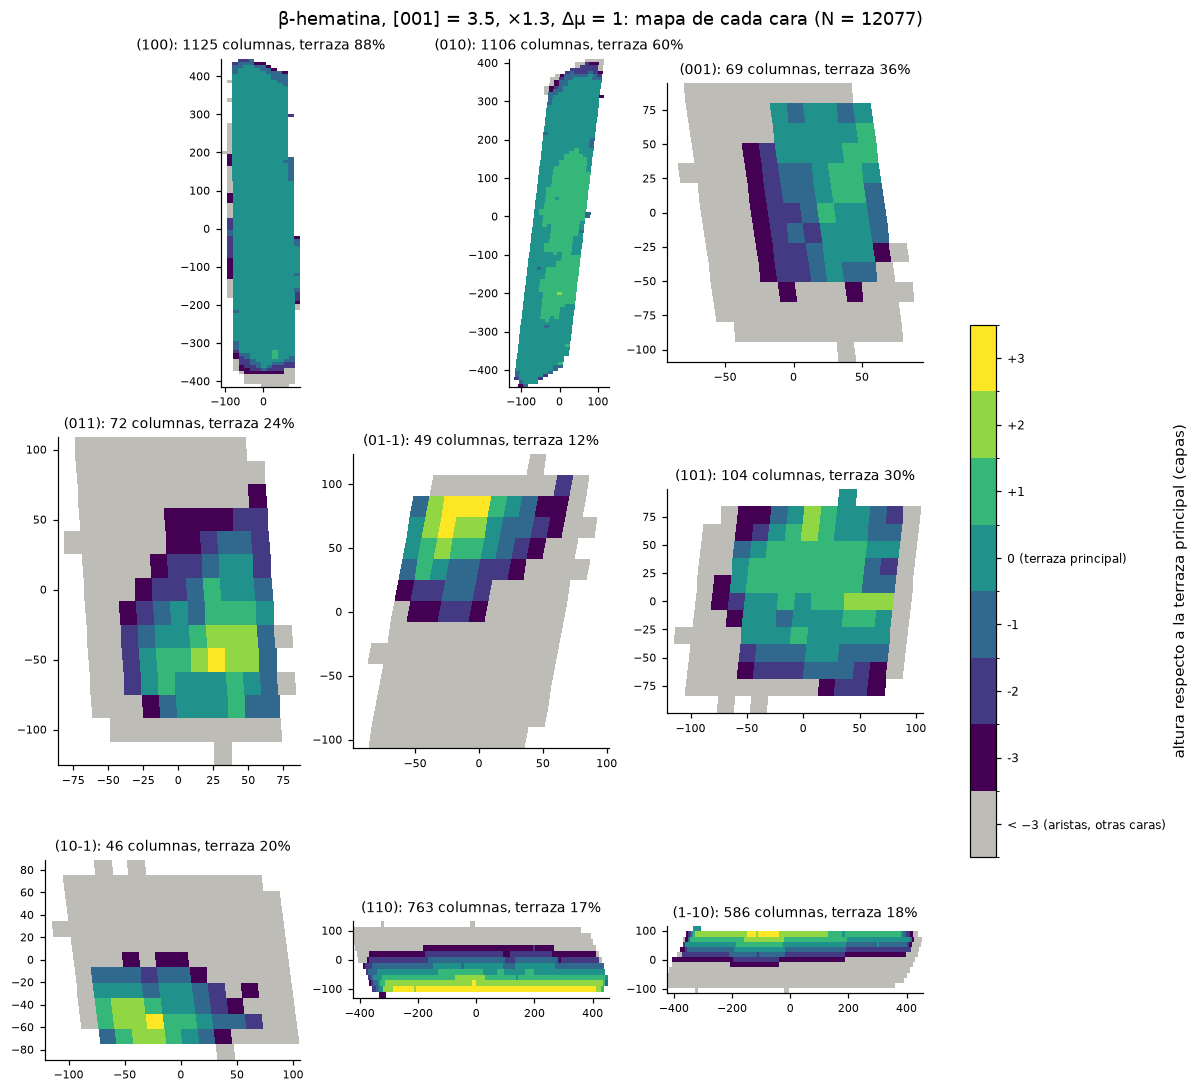

In [ ]:
# Mapa 2D de cada cara del mismo snapshot que la vista de vóxeles (N ≈ 12 000)
axes = viz.plot_face_maps(snaps[i_vox][1], bh.cell, FACES_BH, same_scale=False,
                          title="β-hematina, [001] = 3.5, ×1.3, Δμ = 1: mapa de cada cara "
                                f"(N = {len(snaps[i_vox][1])})")
guardar(axes[0].figure, "bh_mapas_por_cara")
plt.show()

## 6. Superficie de una cara con `src.analysis`

`face_height_map` pasa la cara (hkl) a una base entera de la cara (`face_frame`: u y v
en el plano, w con (hkl)·w = 1). Así se obtiene una matriz de alturas como las de la
línea 2D, y se analiza con `src.analysis.surface_observables`, que da rugosidad W,
densidad de escalones, islas y longitudes de correlación.

Cara (100) de β-hematina, la mayor, a Δμ bajo y alto (tasas simétricas). Ojo:
`src.analysis` supone contorno periódico y el recorte no lo es, así que los
observables con vecinos tienen un error de borde O(1/L).

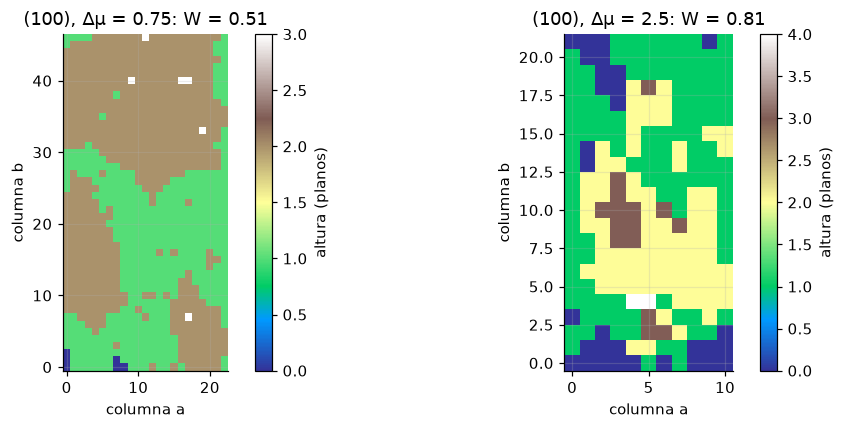

,dmu,Lx,Ly,W,step_density,n_islands,n_eff_levels,xi_r
0,0.75,23,47,0.515,0.136,18,2.094,3.531
1,2.50,11,22,0.810,0.355,11,3.301,2.073


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
obs = []
for ax, dmu in zip(axes, (0.75, 2.5)):
    coords = finales[("symmetric", dmu)]
    hmap = an.face_height_map(coords, (1, 0, 0), crop=0.6)
    o = an.face_surface_observables(coords, (1, 0, 0), crop=0.6)
    obs.append({"dmu": dmu, **{k: o[k] for k in ("Lx", "Ly", "W", "step_density", "n_islands",
                                                   "n_eff_levels", "xi_r")}})
    viz.plot_face_height_map(hmap, ax=ax, title=f"(100), Δμ = {dmu:g}: W = {o['W']:.2f}")
fig.tight_layout()
guardar(fig, "bh_mapa_alturas_100")
plt.show()
pd.DataFrame(obs)

## 7. Probabilidad de unión por tipo de sitio

Es el análogo 3D de la Fig. 8 de Nagpal et al.: la probabilidad de que la próxima unión
ocurra en un sitio con n vecinos ocupados, P_n = M_n k+_n / Σ M k+. Se calcula en el
estado final de cada corrida del §5.1 (`attachment_probabilities`). Con tasas de Gilmer,
k+ es igual en todos los sitios, así que P_n es solo la fracción de sitios. Con tasas
simétricas, k+ ∝ e^{E/2} favorece a los sitios con más enlaces.

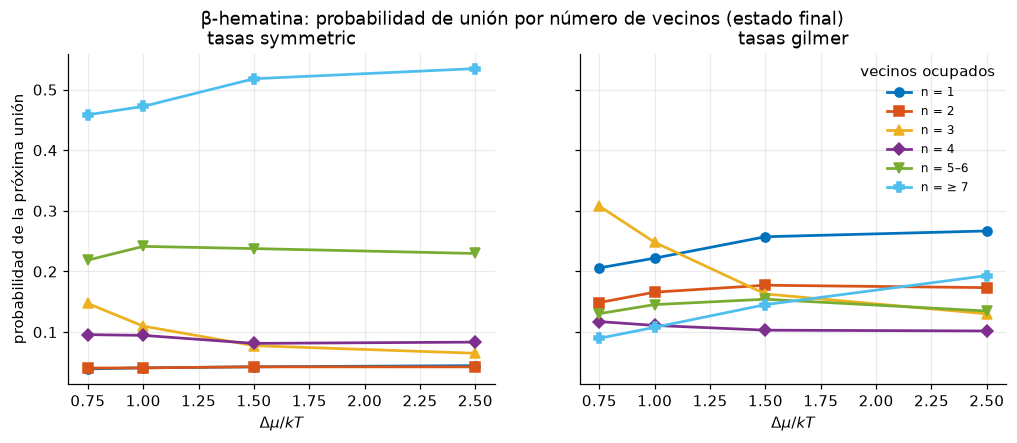

clase               1      2      3      4    5–6    ≥ 7
modelo    dmu                                           
gilmer    0.75  0.206  0.149  0.308  0.117  0.130  0.090
          1.00  0.222  0.166  0.248  0.111  0.145  0.108
          1.50  0.257  0.177  0.163  0.103  0.154  0.145
          2.50  0.267  0.173  0.130  0.102  0.135  0.193
symmetric 0.75  0.039  0.041  0.147  0.096  0.219  0.459
          1.00  0.041  0.041  0.110  0.095  0.241  0.472
          1.50  0.043  0.043  0.078  0.081  0.238  0.518
          2.50  0.045  0.043  0.065  0.083  0.230  0.535

In [18]:
pp = pd.concat(probs, ignore_index=True)
# Agrupación de n (vecinos ocupados, de 1 a 13 en β-hematina) en clases legibles
bins = [(1, 1, "1"), (2, 2, "2"), (3, 3, "3"), (4, 4, "4"), (5, 6, "5–6"), (7, 13, "≥ 7")]
pp["clase"] = None
for lo, hi, lab in bins:
    pp.loc[pp["n_enlaces"].between(lo, hi), "clase"] = lab
tab = (pp.groupby(["modelo", "dmu", "clase"])["P"].sum().unstack("clase")
       .reindex(columns=[b[2] for b in bins]).fillna(0.0))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
for ax, modelo in zip(axes, MODELOS):
    t = tab.loc[modelo]
    for i, lab in enumerate(t.columns):
        ax.plot(t.index, t[lab], color=COLORES[i], marker=MARCAS[i], lw=1.8, label=f"n = {lab}")
    ax.set_xlabel(r"$\Delta\mu / kT$")
    ax.set_title(f"tasas {modelo}")
axes[0].set_ylabel("probabilidad de la próxima unión")
axes[1].legend(frameon=False, fontsize=8, title="vecinos ocupados")
fig.suptitle("β-hematina: probabilidad de unión por número de vecinos (estado final)")
guardar(fig, "bh_probabilidad_union")
plt.show()
tab

## 8. Analizar corridas guardadas

`scripts/run_3d.py` guarda cada corrida en `3DkMC/outputs/<nombre>_dmu_<Δμ>_seed_<s>/`,
con `metadata.json`, `snaps.npz` y `history.csv`. Por ejemplo:

```bash
python 3DkMC/scripts/run_3d.py --config 3DkMC/configs/beta_hematin.json --delta-mu 0.75 1.0 1.5 --seeds 1 2 3
```

Esta celda recorre esas carpetas y resume la velocidad de cada cara (plano externo, a
partir del historial) y la forma final. Si no hay corridas, no hace nada.

In [19]:
from kmc3d.io import load_run

resumen = []
for meta in sorted((ROOT_3D / "outputs").glob("*/metadata.json")):
    r = load_run(meta.parent)
    faces = [tuple(f) for f in r["meta"]["engine_params"]["track_faces"]]
    fila = {"corrida": meta.parent.name, "dmu": r["meta"]["rates"]["delta_mu"],
            "N": len(r["snaps"][-1][1]) if r["snaps"] else np.nan}
    if faces:
        R = an.face_growth_rates(an.face_series(r["history"], r["graph"], faces))
        fila.update(R.groupby("familia", sort=False)["R_rel"].first().to_dict())
    if r["snaps"]:
        sh = an.shape_descriptors(r["snaps"][-1][1], r["graph"].cell)
        fila.update({"L1/L2": sh["L1/L2"], "L2/L3": sh["L2/L3"]})
    resumen.append(fila)
pd.DataFrame(resumen) if resumen else print("No hay corridas en", ROOT_3D / "outputs")

No hay corridas en /home/sggphysics/kMC_Malaria/3DkMC/outputs


In [20]:
print(f"Tiempo total del notebook: {(time.perf_counter() - T0_NOTEBOOK) / 60:.1f} min")

Tiempo total del notebook: 2.4 min


## 9. Conclusiones

**Validación con Kossel**

1. **El tamaño crítico simulado sigue a L\* = 2φ/Δμ** (§3.1).
   - A Δμ = 0.5 se disuelven los cubos de L = 4 y 6 y crecen los de L ≥ 8 (L\* = 8).
   - A Δμ = 0.75 se disuelve el de L = 4 y crece el de L = 6 (L\* ≈ 5.3).
2. **Las caras lisas y las rugosas se comportan distinto** (§3.2).
   - Con φ = 3, la {100} prácticamente no avanza para Δμ ≤ 1 (R/k+ < 0.04): necesita
     nucleación 2D.
   - Con φ = 1 avanza desde el Δμ más bajo.
3. **El modelo 3D no es SOS.** En caras rugosas, R/k+ supera la ley de Wilson-Frenkel:
   1.6 frente a 0.63 con φ = 1 y Δμ = 1. Los lados de los salientes son sitios de unión
   adicionales, y con Gilmer cada uno recibe k+. Es una diferencia de modelo respecto a
   la línea 2D, no un error: los tests comparan el estado incremental con una
   reconstrucción desde cero.
4. **El plano más externo sobrestima R** hasta unas 1.5 veces en caras rugosas (2.5
   frente a 1.65 con φ = 1 y Δμ = 1). Para velocidades hay que usar el plano medio.

**Anisotropía con cubitos.** R(100) : R(010) : R(001) = 1 : 1.66 : 3.04, frente a
1 : 1.5 : 2.5 de E_att. El cristal es una aguja según z (L1/L2 = 1.6). La cinética
amplifica la anisotropía porque la cara lenta es lisa.

**β-hematina (energías provisionales)**

5. **Con las energías provisionales, el kMC no da la aguja observada.** Sale una lámina
   poco alargada (L1/L2 ≈ 1.1–1.3 y L2/L3 ≈ 2 a Δμ ≤ 1). En cambio, la forma de energía
   de unión sí es una aguja según c (L1/L2 ≈ 2). La {010} avanza entre 2.3 y 3.6 veces
   más rápido que la {100}, cuando E_att predice 1.5. Las caras {110}, {1-10} y {101}
   son mucho más lentas de lo que predice E_att.
6. **La forma simulada es estacionaria y coherente con las velocidades medidas.** La
   forma de Wulff cinética construida con las R medidas la reproduce: L1/L2 y L2/L3 =
   1.04 y 2.18 frente a 1.17 y 1.99 con las energías base, y 2.30 y 2.11 frente a 1.99
   y 2.06 con [001] = 3.5.
7. **La anisotropía disminuye al subir Δμ** (rugosidad cinética), con los dos modelos
   de tasas.
8. **Reforzar el apilamiento ([001] = 3.5) da una aguja según c** con L1/L2 ≈ 2. Si
   además se escalan todas las energías ×1.3, sale L1/L2 ≈ 6. Pero entonces la (100)
   casi no crece y el espesor es el de la semilla: la forma de Wulff cinética es una
   lámina de espesor casi nulo, así que no es una forma estacionaria.
9. **La superficie de (100) se analiza con `src.analysis` sin cambios.** La rugosidad W
   pasa de 0.52 a 0.81 y la densidad de escalones de 0.14 a 0.36 entre Δμ = 0.75 y
   Δμ = 2.5.
10. **La probabilidad de unión depende del modelo de tasas.** Con Gilmer solo refleja
    la abundancia de cada tipo de sitio: los de un vecino son el 20–27 %. Con tasas
    simétricas dominan los sitios muy coordinados: los de 5 o más vecinos suman el
    68–77 %. La elección del modelo de tasas (decisión D2 del plan) no es un detalle.

**Siguientes pasos** (ver `PLAN_3DkMC.md`):
- **F3:** calibrar las energías de β-hematina contra la morfología y las velocidades
  experimentales usando el kMC, no solo E_att. La escala global importa tanto como el
  reparto.
- **F2:** modo *slab* para obtener curvas R(Δμ) por cara sin aristas ni efectos de
  tamaño, y comparar con la línea 2D.
- **F4:** difusión superficial y reservorio finito.